# Spiking vs Standard Neural Networks on Handwritten Digits: Unsupervised STDP Learning, Sparsity and Biological Constraints

Neurons in the brain communicate through brief electrical pulses called spikes, and at any moment most neurons are silent. This sparse, event-driven activity is thought to be one reason the whole brain runs on only about 20 watts. Standard artificial neural networks (ANNs) work differently. Every unit computes a continuous number on every input, and the network learns through backpropagation: an error signal is sent backwards through all layers to adjust every weight. Backpropagation is very effective, but it is biologically questionable. A real synapse only has access to the activity of the two neurons it connects, and has no way to receive a global error signal.

Spiking neural networks (SNNs) are closer to biology on both counts. Their neurons are typically modelled as leaky integrate-and-fire units. Voltage builds up as input spikes arrive, leaks away over time, and a spike is fired when a threshold is crossed, after which the neuron briefly rests. Information is carried by the timing and rate of spikes rather than by continuous values. Images are converted into spike trains, so a brighter pixel fires more often, much as a retinal cell signals brightness through its firing rate.

SNNs can also learn with local rules that need no answers. The notebook uses three:

STDP (spike-timing-dependent plasticity): a synapse is strengthened when its input spikes just before the neuron fires and weakened when it spikes just after, which is a timing-based form of Hebb’s “fire together, wire together.”
Lateral inhibition: when one neuron fires it suppresses the others, so neurons compete and each settles on a different pattern.
Adaptive thresholds: a neuron that fires often becomes harder to fire, which acts as a simple form of homeostasis and stops any one neuron dominating.

Because SNN computation is event-driven, work is done only when a spike arrives, and each event needs just an addition. An ANN performs a multiply-and-add at every connection for every input. This is why SNNs are of interest for low-power neuromorphic hardware, although whether they save energy depends on how many spikes a task needs. Finally, the brain works under limits that ANNs usually ignore. Its synapses can hold only a limited number of distinguishable strengths, and it makes decisions quickly, categorising visual input in roughly 150 ms. This raises the question of whether a network that learns the way the brain does is also more robust to such limits.

### Objectives
The notebook builds a small SNN with BindsNET (100 neurons, learning without labels) and compares it to a 784–100–10 ANN on the same 1,500 training and 500 test MNIST images. It addresses three questions:

- Can the SNN learn digit recognition without being told the answers?
- How do the two compare on accuracy, activity and a rough energy estimate?
- How do both cope with brain-like constraints: coarsely rounded synaptic weights and short decision times (10–100 ms)?


**How the code maps onto the brain**
| In the brain | In this notebook |
|---|---|
| A neuron collects input, builds up voltage, fires a spike at threshold, then rests briefly | A "leaky integrate-and-fire" neuron |
| Strength of a synapse | A number called a *weight* |
| Learning from spike timing (Hebb: "fire together, wire together") | The STDP rule |
| Inhibitory interneurons make neighbouring neurons compete | Negative connections between neurons |
| A neuron that fires a lot becomes less excitable (homeostasis) | An adaptive threshold |
| Brighter stimulus gives a higher firing rate, as in retinal cells | Pixel brightness becomes random spike trains |
| Receptive field: the pattern a neuron prefers | The weight "tiles" drawn near the end |

## 1. Setup

In [ ]:
!pip install -q bindsnet "pandas==2.2.3"

import sys, types, collections.abc
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Small compatibility fix so BindsNET works with newer PyTorch (you can ignore this).
mock_six = types.ModuleType('torch._six')
mock_six.container_abcs = collections.abc
mock_six.string_classes = (str,)
mock_six.int_classes = (int,)
sys.modules['torch._six'] = mock_six

from bindsnet.network import Network
from bindsnet.network.nodes import Input, AdaptiveLIFNodes
from bindsnet.network.topology import Connection
from bindsnet.learning import PostPre            # the STDP rule
from bindsnet.encoding import PoissonEncoder
from bindsnet.network.monitors import Monitor

torch.manual_seed(0)
np.random.seed(0)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 6.1 MB/s eta 0:00:00


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Settings and data
Both networks learn from the **same** 1,500 images and are tested on the **same** 500 new images.

In [ ]:
N_TRAIN   = 1500    # images each network learns from
N_TEST    = 500     # new images used for testing
N_NEURONS = 100     # neurons in the spiking network (the ANN also has 100 hidden units)
T         = 100     # milliseconds of "brain time" for each image
MAX_RATE  = 128     # the brightest pixel fires about 128 spikes per second

# The only hardware-flavoured numbers: rough energy cost of one calculation on a chip
# (picojoules, textbook estimates). Used once, for a rough energy comparison.
E_MAC = 4.6   # multiply-and-add (ANN)
E_ADD = 0.9   # addition only (SNN: a spike arrives, its weight is added)

train_set = datasets.MNIST('./data', train=True,  download=True, transform=transforms.ToTensor())
test_set  = datasets.MNIST('./data', train=False, download=True, transform=transforms.ToTensor())
train_idx = torch.randperm(len(train_set))[:N_TRAIN]
test_idx  = torch.randperm(len(test_set))[:N_TEST]

X_train = torch.stack([train_set[int(i)][0] for i in train_idx])
y_train = torch.tensor([train_set[int(i)][1] for i in train_idx])
X_test  = torch.stack([test_set[int(i)][0] for i in test_idx])
y_test  = torch.tensor([test_set[int(i)][1] for i in test_idx])

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 506kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.76MB/s]


## 3. The standard network (ANN)
Layout: 784 inputs (one per pixel), then 100 hidden units, then 10 outputs (one per digit).
Each unit multiplies its inputs by weights and adds them up. A rule called ReLU switches a unit fully *off* (output exactly 0) if its total is negative.

**How it learns:** it is shown the correct answer, and after each guess an error signal is sent backwards through the whole network to adjust every weight (*backpropagation*). Whether brains can do anything like this is still debated, because a real synapse only "knows" about the two neurons it connects.

In [ ]:
ann = nn.Sequential(nn.Flatten(), nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10))
optimizer = torch.optim.Adam(ann.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(5):                        # 5 passes through the training images
    order = torch.randperm(N_TRAIN)
    for start in range(0, N_TRAIN, 32):
        batch = order[start:start + 32]
        loss = loss_fn(ann(X_train[batch]), y_train[batch])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

with torch.no_grad():
    ann_acc = (ann(X_test).argmax(1) == y_test).float().mean().item() * 100
    ann_zero_pct = (ann[:3](X_test) == 0).float().mean().item() * 100   # hidden units that are "off"
ann_ops = 784 * 100 + 100 * 10                # calculations needed per image
print(f"ANN accuracy on new digits: {ann_acc:.0f}%")

ANN accuracy on new digits: 85%


## 4. The spiking network (SNN)
**Input.** Each pixel becomes a random spike train: the brighter the pixel, the more spikes per second (like a retinal cell signalling brightness by its firing rate).

**Neurons.** Each neuron's voltage rises when input spikes arrive, slowly leaks away, and a spike is fired when it crosses a threshold (then a brief rest).

**Three brain-like ingredients make the network learn:**
- **STDP (spike-timing-dependent plasticity).** If an input spikes just *before* the neuron, that synapse is strengthened (LTP). If it spikes just *after*, the synapse is weakened (LTD). Each synapse needs only information about its own two neurons, and no answers are given.
- **Lateral inhibition.** When a neuron fires, it suppresses all the others, so neurons compete and each ends up preferring a *different* pattern.
- **Adaptive threshold.** A neuron that fires a lot becomes harder to fire, so no neuron takes over (a simple form of homeostasis).

In [ ]:
network = Network(dt=1.0)

pixels  = Input(n=784, shape=(1, 28, 28), traces=True)
neurons = AdaptiveLIFNodes(n=N_NEURONS, traces=True, tc_decay=100.0, theta_plus=0.05)
network.add_layer(pixels,  name="Pixels")
network.add_layer(neurons, name="Neurons")

# Pixels -> neurons: start random, then change through STDP
learned = Connection(source=pixels, target=neurons,
                     w=0.3 * torch.rand(784, N_NEURONS),
                     update_rule=PostPre, nu=(1e-4, 1e-2), wmin=0.0, wmax=1.0, norm=78.4)
network.add_connection(learned, source="Pixels", target="Neurons")

# Neurons -> other neurons: fixed negative weights (lateral inhibition)
inhibit = Connection(source=neurons, target=neurons,
                     w=-17.5 * (torch.ones(N_NEURONS, N_NEURONS) - torch.eye(N_NEURONS)),
                     wmin=-17.5, wmax=0.0)
network.add_connection(inhibit, source="Neurons", target="Neurons")

monitor = Monitor(neurons, state_vars=["s"], time=T)    # records every spike
network.add_monitor(monitor, name="Spike Monitor")
encoder = PoissonEncoder(time=T, dt=1.0)

def show_image(img):
    # Show one image for T milliseconds. Returns the input spikes and the neurons' spikes, millisecond by millisecond.
    network.reset_state_variables()
    input_spikes = encoder(img.unsqueeze(0) * MAX_RATE)
    network.run(inputs={"Pixels": input_spikes}, time=T)
    neuron_spikes = monitor.get("s").float().reshape(T, N_NEURONS)
    pixel_spikes = input_spikes.float().reshape(T, -1).sum(1)
    return pixel_spikes, neuron_spikes

# LEARNING: the network only sees images. No answers are given.
print("The SNN is learning...")
train_counts = np.zeros((N_TRAIN, N_NEURONS))        # how many spikes each neuron fired for each image
for i in range(N_TRAIN):
    _, spikes = show_image(X_train[i])
    train_counts[i] = spikes.sum(0).numpy()
    if (i + 1) % 500 == 0:
        print(f"  {i + 1} of {N_TRAIN} images seen")

The SNN is learning...
  500 of 1500 images seen
  1000 of 1500 images seen
  1500 of 1500 images seen


**Reading out what the SNN learned.** Because it was never given answers, its neurons have no labels yet. Neuroscientists face the same problem when they record from a neuron: they find its *preferred stimulus*. We do the same: each neuron is named after the digit it fired for most. To classify a new image, we see which digit's group of neurons fired the most. (This is the only place the answers are used.)

In [ ]:
labels = y_train.numpy()
average_response = np.stack([train_counts[labels == d].mean(axis=0) for d in range(10)])   # digit x neuron
preferred_digit = average_response.argmax(axis=0)       # each neuron's favourite digit

def classify(spike_counts):
    score = [spike_counts[preferred_digit == d].mean() if (preferred_digit == d).any() else 0
             for d in range(10)]
    return int(np.argmax(score))

## 5. Testing on new digits
We switch learning **off** (so the test is clean) and show 500 unseen digits. For each one we record:
- the **answer** (which digit's neurons fired the most),
- the **activity** (how many spikes were fired),
- the **work done**: a *synaptic event* is every time a spike arrives at a synapse. The ANN does a calculation at every synapse for every image, but the SNN only does work when a spike actually arrives.

We also record the answer after only 10, 25, 50 and 100 ms. This shows how accuracy builds up as spikes accumulate.

In [ ]:
network.train(False)                          # learning off
network.learning = False
neurons.theta_plus = torch.tensor(0.0)        # thresholds stop adapting too
trained_weights = learned.w.clone()           # remember what was learned

TIMES_TO_TEST = [10, 25, 50, 100]

def coarsen(w, steps):
    # Round weights to only a few allowed values ("steps" = how many notches the strength dial has).
    scale = w.abs().max()
    return torch.round(w / scale * steps) / steps * scale

def test_snn(steps=None):
    # Test the SNN (steps=None means the full-precision weights it learned).
    weights = trained_weights if steps is None else coarsen(trained_weights, steps)
    right  = {t: 0 for t in TIMES_TO_TEST}
    events = {t: [] for t in TIMES_TO_TEST}
    spikes_fired = {t: [] for t in TIMES_TO_TEST}
    for i in range(N_TEST):
        learned.w.data.copy_(weights)                     # reset the weights before every image so nothing can drift
        pixel_spikes, neuron_spikes = show_image(X_test[i])
        pixels_so_far  = pixel_spikes.cumsum(0).numpy()   # running totals, millisecond by millisecond
        neurons_so_far = neuron_spikes.cumsum(0).numpy()
        for t in TIMES_TO_TEST:
            counts = neurons_so_far[t - 1]
            right[t] += int(classify(counts) == int(y_test[i]))
            events[t].append(pixels_so_far[t - 1] * N_NEURONS + counts.sum() * (N_NEURONS - 1))
            spikes_fired[t].append(counts.sum())
    learned.w.data.copy_(trained_weights)                 # put the learned weights back
    # for each time: (accuracy %, energy in nJ, synaptic events per image, neuron spikes per image)
    return {t: (right[t] / N_TEST * 100, np.mean(events[t]) * E_ADD / 1000, np.mean(events[t]), np.mean(spikes_fired[t]))
            for t in TIMES_TO_TEST}

print("Testing the SNN...")
snn_full = test_snn()
print("Done.")

Testing the SNN...
Done.


## 6. Results: the two networks side by side

In [ ]:
snn_acc, snn_nJ, snn_events, snn_spikes = snn_full[T]
ann_nJ = ann_ops * E_MAC / 1000
snn_active = snn_spikes / (N_NEURONS * T) * 100          # % of (neuron, millisecond) slots containing a spike
rate_hz = snn_spikes / N_NEURONS / (T / 1000)            # average spikes per neuron per second

print(f"ACCURACY on new digits       standard network: {ann_acc:.0f}%      spiking network: {snn_acc:.0f}%")
print(f"ACTIVITY (units 'on')        standard network: {100 - ann_zero_pct:.0f}% of units      spiking network: {snn_active:.1f}% of time slots")
print(f"FIRING RATE                  spiking neurons fire {rate_hz:.1f} spikes/s on average (real cortex: roughly 1-10)")
print(f"WORK PER IMAGE               standard network: {ann_ops:,} calculations      spiking network: {snn_events:,.0f} synaptic events")
print(f"ROUGH ENERGY PER IMAGE       standard network: {ann_nJ:.0f} nJ      spiking network: {snn_nJ:.0f} nJ")

ACCURACY on new digits       standard network: 85%      spiking network: 45%
ACTIVITY (units 'on')        standard network: 79% of units      spiking network: 0.2% of time slots
FIRING RATE                  spiking neurons fire 2.2 spikes/s on average (real cortex: roughly 1-10)
WORK PER IMAGE               standard network: 79,400 calculations      spiking network: 129,170 synaptic events
ROUGH ENERGY PER IMAGE       standard network: 365 nJ      spiking network: 116 nJ


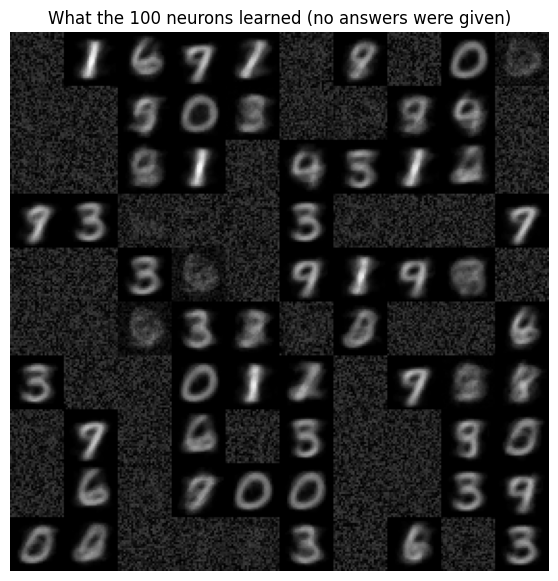

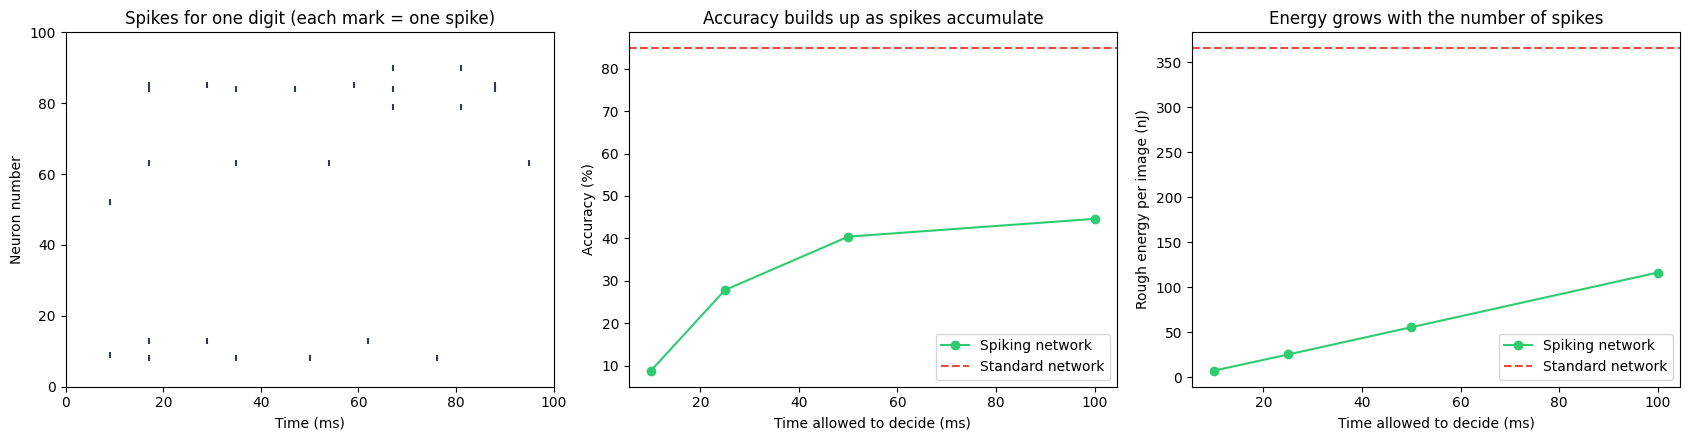

In [ ]:
# Figure 1: what did each neuron learn? Each tile is the pattern of synapse strengths onto one neuron.
w = learned.w.detach().cpu().numpy().reshape(28, 28, N_NEURONS)
tiles = np.vstack([np.hstack([w[:, :, r * 10 + c] for c in range(10)]) for r in range(10)])
plt.figure(figsize=(7, 7))
plt.imshow(tiles, cmap="gray")
plt.axis("off")
plt.title("What the 100 neurons learned (no answers were given)")
plt.show()

# Figure 2: spikes for one image, how accuracy grows with time, and energy
_, one_image = show_image(X_test[0])
t_spk, n_spk = torch.where(one_image > 0)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4.5))
a1.scatter(t_spk.numpy(), n_spk.numpy(), s=25, color="#2c3e50", marker="|")
a1.set_xlim(0, T); a1.set_ylim(0, N_NEURONS)
a1.set_xlabel("Time (ms)"); a1.set_ylabel("Neuron number")
a1.set_title("Spikes for one digit (each mark = one spike)")

a2.plot(TIMES_TO_TEST, [snn_full[t][0] for t in TIMES_TO_TEST], "o-", color="#2ecc71", label="Spiking network")
a2.axhline(ann_acc, color="#e74c3c", linestyle="--", label="Standard network")
a2.set_xlabel("Time allowed to decide (ms)"); a2.set_ylabel("Accuracy (%)")
a2.set_title("Accuracy builds up as spikes accumulate")
a2.legend()

a3.plot(TIMES_TO_TEST, [snn_full[t][1] for t in TIMES_TO_TEST], "o-", color="#2ecc71", label="Spiking network")
a3.axhline(ann_nJ, color="#e74c3c", linestyle="--", label="Standard network")
a3.set_xlabel("Time allowed to decide (ms)"); a3.set_ylabel("Rough energy per image (nJ)")
a3.set_title("Energy grows with the number of spikes")
a3.legend()
plt.tight_layout()
plt.show()

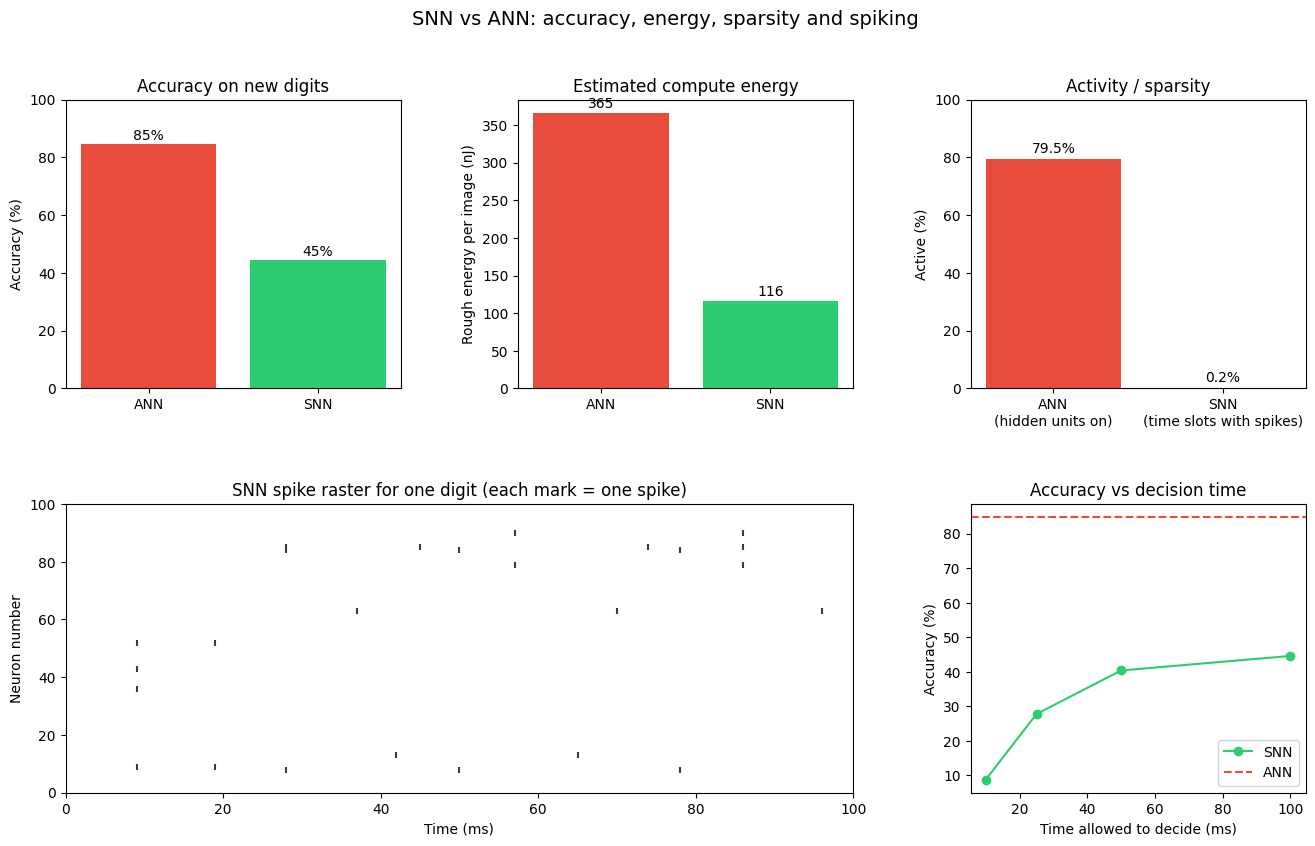

In [ ]:
# Figures: SNN vs ANN side-by-side (bar charts) + SNN spike raster
_, one_image = show_image(X_test[0])          # run one test digit through the SNN
t_spk, n_spk = torch.where(one_image > 0)     # spike times and neuron ids

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

# --- Bar 1: accuracy ---
ax = fig.add_subplot(gs[0, 0])
bars = ax.bar(["ANN", "SNN"], [ann_acc, snn_acc], color=["#e74c3c", "#2ecc71"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy on new digits")
ax.set_ylim(0, 100)
for b, v in zip(bars, [ann_acc, snn_acc]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center")

# --- Bar 2: rough energy per image ---
ax = fig.add_subplot(gs[0, 1])
bars = ax.bar(["ANN", "SNN"], [ann_nJ, snn_nJ], color=["#e74c3c", "#2ecc71"])
ax.set_ylabel("Rough energy per image (nJ)")
ax.set_title("Estimated compute energy")
top = max(ann_nJ, snn_nJ)
for b, v in zip(bars, [ann_nJ, snn_nJ]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02 * top, f"{v:.0f}", ha="center")

# --- Bar 3: activity / sparsity ---
ax = fig.add_subplot(gs[0, 2])
ann_active = 100 - ann_zero_pct                # % of ANN hidden units that are "on"
bars = ax.bar(["ANN\n(hidden units on)", "SNN\n(time slots with spikes)"],
              [ann_active, snn_active], color=["#e74c3c", "#2ecc71"])
ax.set_ylabel("Active (%)")
ax.set_title("Activity / sparsity")
ax.set_ylim(0, 100)
for b, v in zip(bars, [ann_active, snn_active]):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.1f}%", ha="center")

# --- SNN spike raster (spans two columns) ---
ax = fig.add_subplot(gs[1, :2])
ax.scatter(t_spk.numpy(), n_spk.numpy(), s=25, color="#2c3e50", marker="|")
ax.set_xlim(0, T)
ax.set_ylim(0, N_NEURONS)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Neuron number")
ax.set_title("SNN spike raster for one digit (each mark = one spike)")

# --- Accuracy vs decision time ---
ax = fig.add_subplot(gs[1, 2])
ax.plot(TIMES_TO_TEST, [snn_full[t][0] for t in TIMES_TO_TEST],
        "o-", color="#2ecc71", label="SNN")
ax.axhline(ann_acc, color="#e74c3c", linestyle="--", label="ANN")
ax.set_xlabel("Time allowed to decide (ms)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy vs decision time")
ax.legend()

fig.suptitle("SNN vs ANN: accuracy, energy, sparsity and spiking", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 7. Impose Rudimentary Limits
Brains work with imprecise parts and decide quickly. We test two limits:
1. **Imprecise synapses.** A real synapse cannot hold an infinitely fine strength. One study of hippocampal synapses found only about two dozen distinguishable sizes. We round every weight to a few allowed values (`steps` = notches on the strength dial; fewer steps = cruder synapse).
2. **Fast decisions.** The human visual system can categorise what it sees in roughly 150 ms. We already measured accuracy at short times above.

In [ ]:
STEPS_TO_TEST = [None, 15, 3]     # None = full precision; then 15 notches; then only 3 notches

def ann_accuracy(steps):
    saved = [p.detach().clone() for p in ann.parameters()]
    with torch.no_grad():
        if steps is not None:
            for layer in ann:
                if isinstance(layer, nn.Linear):
                    layer.weight.copy_(coarsen(layer.weight, steps))
        acc = (ann(X_test).argmax(1) == y_test).float().mean().item() * 100
        for p, s in zip(ann.parameters(), saved):          # put the original weights back
            p.copy_(s)
    return acc

ann_by_steps = {s: ann_accuracy(s) for s in STEPS_TO_TEST}
snn_by_steps = {None: snn_full}
for s in STEPS_TO_TEST:
    if s is not None:
        print(f"Testing SNN with {s} notches...")
        snn_by_steps[s] = test_snn(s)

print("\nACCURACY (%) when synapse strengths are rounded")
print(f"{'notches':>9} | {'standard net':>12} | spiking network, by time allowed: " + "  ".join(f"{t:>3} ms" for t in TIMES_TO_TEST))
for s in STEPS_TO_TEST:
    name = "full" if s is None else str(s)
    row = "  ".join(f"{snn_by_steps[s][t][0]:>6.0f}" for t in TIMES_TO_TEST)
    print(f"{name:>9} | {ann_by_steps[s]:>11.0f}% | {'':<33}{row}")

Testing SNN with 15 notches...
Testing SNN with 3 notches...

ACCURACY (%) when synapse strengths are rounded
  notches | standard net | spiking network, by time allowed:  10 ms   25 ms   50 ms  100 ms
     full |          85% |                                       9      28      40      45
       15 |          85% |                                      10      27      37      43
        3 |          86% |                                      10      26      41      45


# 8. Results
In the recorded run, the ANN reached 85% and the SNN 45%. The SNN was very sparse (about 0.2% of time slots active) and had a lower estimated energy cost (116 nJ versus 365 nJ per image). Its accuracy was unaffected by rounding the weights to as few as 3 levels, and it improved as more decision time was allowed.

### Notes on the above
- If accuracy barely changes when synapses are rounded, the learned information lies in the *pattern* (which synapses are strong and which are weak), not in fine detail. STDP tends to push synapses towards strong or weak, so a spiking network can be robust to crude synapses, as real networks must be.
- A standard network trained with exact numbers and then rounded may lose accuracy when the rounding is very crude, because it was never trained to cope with that.
- Faster decisions cost accuracy in the spiking network at every precision, as in the time plot above.

## 9. Summary
- A small spiking network, using only local, timing-based learning and **no answers**, developed digit-like receptive fields and recognised digits well above chance.
- A standard network trained with answers is more accurate in this small setting, but the spiking network is sparse, fires at brain-like rates, and its cost depends on how many spikes it needs.
- The spiking network trades **time for accuracy**: more time means more evidence, as in decision-making in the brain. Its learned patterns also survive crude synapses, which suits a system whose synapses are imprecise.

*Limits of this run:* a single small run on one dataset; the energy values are rough estimates, not hardware measurements.